# ManaTrade — Adequação de cartas a decks Commander
**FS26S — Fundamentos de Sistemas Inteligentes · UTFPR-DV · Projeto Prático (TP)**

Equipe: _preencher nomes_

**Problema (≤5 linhas).** Jogadores de Magic: The Gathering trocam cartas sem saber se a carta recebida serve no deck
que estão montando. Dado um deck de Commander e uma carta candidata, queremos **prever se a carta pertenceria ao deck**
usando apenas características da carta, do deck e da interação carta×deck. A probabilidade prevista vira um *score de
adequação* usado pelo app ManaTrade para sugerir trocas ("esta carta melhora o deck; remova X").

**Tarefa de ML:** classificação binária supervisionada. Instância = par (deck, carta candidata).

**Rótulo:** 1 se a carta está na lista oficial do deck; 0 se é legal em Commander, compatível com a identidade de cor do
deck, mas ausente dele (negativo "difícil", ver Seção 4).

**Limitação central (declarada desde já):** o modelo aprende *o que os designers/jogadores costumam incluir*, não a
verdade absoluta sobre o poder de uma carta. Um 0 significa "não foi escolhida", não "seria ruim".

## 0. Sumário
1. Configuração e reprodutibilidade
2. Carregamento dos dados (Scryfall + MTGJSON)
3. Análise exploratória (EDA)
4. Definição do rótulo e construção dos pares com negativos difíceis
5. Engenharia de features (carta, deck, interação) e EDA das features
6. Protocolo experimental e prevenção de vazamento
7. Etapa 1: baseline + regressão logística (divisão treino/teste por deck)
8. Comparação de modelos com validação cruzada agrupada (k=5)
9. Avaliação no conjunto de teste, top-k recall e visualizações
10. Importância de features e ablação da popularidade
11. Regra de remoção e teste prático
12. Exportação do modelo (joblib)
13. Análise crítica, limitações e próximos passos

## 1. Configuração e reprodutibilidade
Usamos apenas numpy, pandas, matplotlib, seaborn e scikit-learn. Toda aleatoriedade usa `random_state=42`.

O código de features fica num pequeno pacote `manatrade_ml`, gravado pelas células `%%writefile` abaixo. Isso permite
que **o mesmo código** seja usado aqui e no backend do aplicativo (que carrega o modelo exportado), evitando divergência
entre treino e produção.

In [1]:
import os, sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.exceptions import UndefinedMetricWarning
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)  # baseline de classe majoritária não prevê positivos (precisão indefinida = 0)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
Path("manatrade_ml").mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


In [2]:
%%writefile manatrade_ml/__init__.py
"""Pacote de features e pré-processamento do TP (FS26S) — ManaTrade.

Fonte única do código usado pelo notebook (ml/notebooks/manatrade_tp.ipynb) e
pelo backend de inferência (backend-ml/). Tudo aqui é determinístico.
"""
from .features import *  # noqa: F401,F403

Overwriting manatrade_ml/__init__.py


In [3]:
%%writefile manatrade_ml/features.py
"""Features de carta, deck e interação carta×deck + codificador de popularidade."""
import re
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

RANDOM_STATE = 42
COLORS = list("WUBRG")
TYPES = ["creature", "instant", "sorcery", "artifact", "enchantment", "planeswalker", "land", "battle"]
RARITY = {"common": 0, "uncommon": 1, "rare": 2, "special": 2, "bonus": 2, "mythic": 3}
# Palavras-chave mais frequentes no catálogo Commander (escolha fixa, independente do alvo).
KEYWORDS = ["flying", "trample", "haste", "vigilance", "deathtouch", "lifelink", "flash",
            "reach", "menace", "first strike", "ward", "equip", "scry", "mill", "landfall"]
# Tags de papel extraídas do texto de regras por expressões regulares simples.
ROLE_PATTERNS = {
    "ramp": r"add \{|search your library for (a|up to \w+) (basic )?land|put (a|that|those) land cards? onto the battlefield|additional land",
    "draw": r"draws? (a|two|three|x|\w+) cards?|draw cards? equal",
    "removal": r"destroy target|exile target (creature|artifact|enchantment|permanent|nonland)|deals? \S+ damage to (target|any target|each creature)|target creature gets -",
    "wipe": r"destroy all|exile all|all creatures get -|each creature gets -|deals? \S+ damage to each creature",
    "counter": r"counter target",
    "tutor": r"search your library for a(n)? (?!basic)(?!land)",
    "token": r"create (a|an|one|two|three|x|\w+) .*?tokens?",
    "recursion": r"return .* from (your|a) graveyard",
    "protection": r"hexproof|indestructible|protection from|phase out",
    "lifegain": r"gain \S+ life|you gain life",
    "counters": r"\+1/\+1 counter",
    "sacrifice": r"sacrifice (a|another|an)",
}
ROLES = list(ROLE_PATTERNS)
_ROLE_RE = {k: re.compile(v) for k, v in ROLE_PATTERNS.items()}
BASIC_NAMES = {"Plains", "Island", "Swamp", "Mountain", "Forest", "Wastes"}


def _num(s):
    try:
        return float(s)
    except (TypeError, ValueError):
        return np.nan


def card_features(cards: pd.DataFrame) -> pd.DataFrame:
    """Uma linha por carta (indexada por oracle_id) com as features da carta."""
    c = cards.copy()
    text = c["oracle_text"].fillna("").str.lower()
    tl = c["type_line"].fillna("").str.lower()
    mc = c["mana_cost"].fillna("")
    out = pd.DataFrame(index=c["oracle_id"].values)
    out["cmc"] = c["cmc"].fillna(0).values
    for col in COLORS:
        out[f"pip_{col}"] = mc.str.count(r"\{[^}]*" + col + r"[^}]*\}").values
        out[f"ci_{col}"] = c["color_identity"].fillna("").str.contains(col).astype(int).values
    out["n_ci"] = out[[f"ci_{x}" for x in COLORS]].sum(1)
    out["pip_generic"] = mc.str.extractall(r"\{(\d+)\}")[0].astype(float).groupby(level=0).sum().reindex(range(len(c)), fill_value=0).values
    for t in TYPES:
        out[f"is_{t}"] = tl.str.contains(t).astype(int).values
    out["is_legendary"] = tl.str.contains("legendary").astype(int).values
    for name, col in (("power", "power"), ("toughness", "toughness"), ("loyalty", "loyalty")):
        v = c[col].map(_num).values
        out[name] = v  # NaN quando não se aplica / "*" -> imputado no Pipeline
    out["rarity"] = c["rarity"].map(RARITY).fillna(1).values
    kw = c["keywords"].fillna("").str.lower()
    out["n_keywords"] = kw.map(lambda s: 0 if not s else len(s.split("|"))).values
    for k in KEYWORDS:
        out[f"kw_{k.replace(' ', '_')}"] = kw.str.contains(rf"(?:^|\|){k}(?:\||$)").astype(int).values
    for r, rx in _ROLE_RE.items():
        out[f"role_{r}"] = text.map(lambda s, rx=rx: int(bool(rx.search(s)))).values
    out["text_len"] = text.str.len().values
    out["log_edhrec_rank"] = np.log1p(c["edhrec_rank"].values)  # NaN = carta sem rank (imputado)
    out["subtypes"] = c["type_line"].fillna("").map(lambda s: s.split("—")[1].strip() if "—" in s else "").values
    out["color_identity"] = c["color_identity"].fillna("").values
    out["name"] = c["name"].values
    return out


# Colunas numéricas da carta agregadas no nível do deck.
DECK_AGG_COLS = (["cmc"] + [f"pip_{x}" for x in COLORS] + [f"is_{t}" for t in TYPES]
                 + [f"role_{r}" for r in ROLES])
CMC_BINS = [(0, 1), (2, 2), (3, 3), (4, 4), (5, 99)]


def _deck_sum_vectors(cf: pd.DataFrame, decks: pd.DataFrame):
    """Somas por deck (com multiplicidade) usadas para médias com exclusão da própria carta."""
    base = cf[DECK_AGG_COLS].copy()
    nonland = 1 - cf["is_land"]
    base["nonland"] = nonland
    base["cmc_nonland"] = cf["cmc"] * nonland
    for lo, hi in CMC_BINS:
        base[f"cmcbin_{lo}_{hi}"] = ((cf["cmc"] >= lo) & (cf["cmc"] <= hi) & (nonland == 1)).astype(int)
    m = decks.merge(base, left_on="oracle_id", right_index=True)
    cols = list(base.columns)
    sums = m[cols].mul(m["count"], axis=0).groupby(m["deck_id"]).sum()
    sums["n_cards"] = m.groupby("deck_id")["count"].sum()
    return base, sums


def deck_subtypes(cf, decks):
    m = decks.merge(cf[["subtypes"]], left_on="oracle_id", right_index=True)
    return m.groupby("deck_id")["subtypes"].apply(lambda s: " ".join(s).split())


def build_features(pairs: pd.DataFrame, cf: pd.DataFrame, decks: pd.DataFrame, deck_ci: pd.Series) -> pd.DataFrame:
    """Monta a matriz de features para pares (deck_id, oracle_id).

    `decks` = composição dos 99 (sem comandante) de cada deck. A carta `anchor_id`
    (se houver e pertencer ao deck) é removida dos agregados do deck. Nos positivos
    anchor = a própria carta; nos negativos, anchor = o positivo para o qual foram
    sorteados. Assim positivo e negativos veem o MESMO contexto (deck com uma vaga
    aberta); sem isso, só os positivos teriam n-1 cartas e o modelo aprenderia o
    rótulo pelo denominador (vazamento detectado na árvore de decisão).
    Na inferência sem anchor_id, uma candidata que já está no deck é removida dele.
    """
    base, sums = _deck_sum_vectors(cf, decks)
    member = decks.groupby(["deck_id", "oracle_id"])["count"].sum()
    p = pairs[["deck_id", "oracle_id"]].copy()
    anchor = pairs["anchor_id"].values if "anchor_id" in pairs else p["oracle_id"].values
    idx = pd.MultiIndex.from_arrays([p["deck_id"].values, anchor])
    cnt = member.reindex(idx).fillna(0).values
    S = sums.reindex(p["deck_id"]).values - base.reindex(anchor).reindex(columns=list(sums.columns), fill_value=0).values * cnt[:, None]
    S = pd.DataFrame(S, columns=sums.columns, index=p.index)
    # n_cards: remove as cópias da própria carta
    S["n_cards"] = sums["n_cards"].reindex(p["deck_id"]).values - cnt
    n, nl = S["n_cards"].clip(lower=1), S["nonland"].clip(lower=1)
    X = cf.reindex(p["oracle_id"]).drop(columns=["subtypes", "color_identity", "name"]).reset_index(drop=True)
    X.index = p.index
    D = pd.DataFrame(index=p.index)
    D["deck_mean_cmc"] = S["cmc_nonland"] / nl
    pip_tot = S[[f"pip_{c}" for c in COLORS]].sum(1).clip(lower=1)
    for c in COLORS:
        D[f"deck_pipshare_{c}"] = S[f"pip_{c}"] / pip_tot
    for t in TYPES:
        D[f"deck_frac_{t}"] = S[f"is_{t}"] / n
    for r in ROLES:
        D[f"deck_frac_role_{r}"] = S[f"role_{r}"] / n
    for lo, hi in CMC_BINS:
        D[f"deck_cmcbin_{lo}_{hi}"] = S[f"cmcbin_{lo}_{hi}"] / nl
    dci = deck_ci.reindex(p["deck_id"]).fillna("").values
    D["deck_n_ci"] = [len(s) for s in dci]
    # Interação carta×deck
    I = pd.DataFrame(index=p.index)
    card_pips = X[[f"pip_{c}" for c in COLORS]].values
    shares = D[[f"deck_pipshare_{c}" for c in COLORS]].values
    tot = card_pips.sum(1)
    I["int_pip_affinity"] = np.where(tot > 0, (card_pips * shares).sum(1) / np.maximum(tot, 1), np.nan)
    cci = cf["color_identity"].reindex(p["oracle_id"]).fillna("").values
    I["int_ci_fraction"] = [len(set(a)) / max(len(b), 1) for a, b in zip(cci, dci)]
    I["int_ci_outside"] = [int(not set(a) <= set(b)) for a, b in zip(cci, dci)]
    I["int_cmc_diff"] = X["cmc"].values - D["deck_mean_cmc"].values
    I["int_abs_cmc_diff"] = np.abs(I["int_cmc_diff"])
    same_type = np.zeros(len(p))
    for t in TYPES:
        same_type += X[f"is_{t}"].values * D[f"deck_frac_{t}"].values
    I["int_same_type_frac"] = same_type
    rc = X[[f"role_{r}" for r in ROLES]].values
    rd = D[[f"deck_frac_role_{r}" for r in ROLES]].values
    I["int_same_role_frac"] = (rc * rd).sum(1)
    num = (rc * rd).sum(1)
    den = np.linalg.norm(rc, axis=1) * np.linalg.norm(rd, axis=1)
    I["int_role_cosine"] = np.where(den > 0, num / np.where(den > 0, den, 1), 0)
    # sobreposição de subtipos (tribal): quantas cartas do deck compartilham subtipo com a candidata
    dsub = deck_subtypes(cf, decks)
    csub = cf["subtypes"].reindex(p["oracle_id"]).fillna("").values
    asub = cf["subtypes"].reindex(anchor).fillna("").values
    ov = []
    for d, s, a, k in zip(p["deck_id"].values, csub, asub, cnt):
        toks = s.split()
        if not toks:
            ov.append(0.0)
            continue
        pool = dsub.get(d, [])
        hits = sum(1 for t in pool if t in toks) - k * sum(1 for t in a.split() if t in toks)
        ov.append(max(hits, 0) / 99.0)
    I["int_subtype_overlap"] = ov
    return pd.concat([X, D, I], axis=1)


class TrainPopularityEncoder(BaseEstimator, TransformerMixin):
    """Popularidade da carta calculada SOMENTE com os decks de treino.

    pop(c) = nº de decks de treino que contêm c / nº de decks de treino cuja
    identidade de cor permite c. Em fit_transform (linhas de treino) usa
    leave-one-deck-out: o deck da própria linha não conta, evitando que o rótulo
    vaze pela feature. Recebe DataFrame com colunas deck_id, oracle_id,
    card_ci, deck_ci; devolve as demais colunas + 'train_pop'.
    """

    id_cols = ["deck_id", "oracle_id", "card_ci", "deck_ci"]

    def __init__(self, prior: float = 1.0):
        self.prior = prior

    def fit(self, X, y=None):
        X = X.reset_index(drop=True)
        y = np.asarray(y)
        pos = X.loc[y == 1, ["deck_id", "oracle_id"]].drop_duplicates()
        self.contain_ = pos.groupby("oracle_id").size().to_dict()
        self.deck_cis_ = X.drop_duplicates("deck_id").set_index("deck_id")["deck_ci"].to_dict()
        ci_counts = pd.Series(list(self.deck_cis_.values())).value_counts().to_dict()
        self.ci_counts_ = ci_counts
        self.pos_pairs_ = set(map(tuple, pos.values))
        return self

    def _eligible(self, card_ci):
        s = set(card_ci)
        return sum(n for ci, n in self.ci_counts_.items() if s <= set(ci))

    def _pop(self, X, loo):
        cache = {}
        vals = np.empty(len(X))
        for i, (d, o, cci) in enumerate(zip(X["deck_id"].values, X["oracle_id"].values, X["card_ci"].fillna("").values)):
            if cci not in cache:
                cache[cci] = self._eligible(cci)
            n_el = cache[cci]
            k = self.contain_.get(o, 0)
            if loo and d in self.deck_cis_:
                n_el -= int(set(cci) <= set(self.deck_cis_[d]))
                k -= int((d, o) in self.pos_pairs_)
            vals[i] = (k + 0.0) / (n_el + self.prior)
        return vals

    def _out(self, X, loo):
        out = X.drop(columns=self.id_cols).copy()
        out["train_pop"] = self._pop(X, loo)
        return out

    def transform(self, X):
        return self._out(X, loo=False)

    def fit_transform(self, X, y=None, **kw):
        return self.fit(X, y)._out(X, loo=True)


class ColumnSelector(BaseEstimator, TransformerMixin):
    """Mantém apenas `columns` (None = todas). Usado nas ablações; serializável com joblib."""

    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X if self.columns is None else X[list(self.columns)]

Overwriting manatrade_ml/features.py


In [4]:
%%writefile manatrade_ml/pairs.py
"""Construção do dataset de pares (deck, carta) com negativos difíceis."""
import numpy as np
import pandas as pd
from .features import BASIC_NAMES, RANDOM_STATE


def dedup_and_group(decks: pd.DataFrame, jaccard_threshold: float = 0.5):
    """Remove decks idênticos (reimpressões) e agrupa decks muito parecidos.

    Retorna (decks_filtrados, group_id por deck_id). Decks com Jaccard >= limiar
    caem no mesmo grupo e, portanto, sempre no mesmo lado da divisão treino/teste.
    """
    main = decks[decks.is_commander == 0]
    sets = main.groupby("deck_id")["oracle_id"].apply(frozenset)
    keep = sets[~sets.duplicated()].index
    sets = sets.loc[keep]
    ids = list(sets.index)
    parent = {d: d for d in ids}

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for i in range(len(ids)):
        for j in range(i + 1, len(ids)):
            a, b = sets[ids[i]], sets[ids[j]]
            if len(a & b) / len(a | b) >= jaccard_threshold:
                parent[find(ids[i])] = find(ids[j])
    groups = pd.Series({d: find(d) for d in ids})
    groups = groups.map({g: k for k, g in enumerate(sorted(groups.unique()))})
    return decks[decks.deck_id.isin(keep)].copy(), groups


def make_pairs(decks, cards, deck_ci, neg_ratio=3, cmc_tol=1, seed=RANDOM_STATE):
    """Positivos: cartas não-básicas dos 99 de cada deck (sem o comandante).

    Negativos difíceis: para cada positivo, `neg_ratio` cartas legais em Commander,
    dentro da identidade de cor do deck, ausentes dele, do mesmo grupo terreno/não
    terreno, com |CMC - CMC do positivo| <= cmc_tol e preferindo a mesma identidade
    de cor do positivo. Relaxa a restrição de cor se faltar candidato.
    """
    rng = np.random.default_rng(seed)
    pool = cards[(cards.legal_commander == "legal") & (~cards.name.isin(BASIC_NAMES))
                 & (~cards.type_line.fillna("").str.contains("Basic Land"))].copy()
    pool["ci"] = pool.color_identity.fillna("")
    pool["is_land"] = pool.type_line.fillna("").str.contains("Land") & ~pool.type_line.fillna("").str.contains("//")
    info = pool.set_index("oracle_id")
    rows = []
    for d, g in decks[decks.is_commander == 0].groupby("deck_id"):
        dci = set(deck_ci[d])
        in_deck = set(g.oracle_id)
        allowed = pool[pool.ci.map(lambda s: set(s) <= dci) & ~pool.oracle_id.isin(in_deck)]
        used = set()
        pos = [o for o in g.oracle_id.unique() if o in info.index]
        for o in pos:
            rows.append((d, o, 1, o))
            pc = info.loc[o]
            cand = allowed[(allowed.is_land == pc.is_land) & ((allowed.cmc - pc.cmc).abs() <= cmc_tol)]
            pref = cand[cand.ci == pc.ci]
            for src in (pref, cand, allowed):
                src = src[~src.oracle_id.isin(used)]
                if len(src) >= neg_ratio:
                    break
            pick = src.oracle_id.values[rng.choice(len(src), size=min(neg_ratio, len(src)), replace=False)]
            used.update(pick)
            rows += [(d, n, 0, o) for n in pick]
    # anchor_id: positivo "escondido" do deck; os 3 negativos sorteados para ele
    # competem pela mesma vaga e veem exatamente o mesmo contexto de deck.
    return pd.DataFrame(rows, columns=["deck_id", "oracle_id", "label", "anchor_id"])

Overwriting manatrade_ml/pairs.py


In [5]:
%%writefile manatrade_ml/recommend.py
"""Montagem de X para o Pipeline e regra de remoção (usado no notebook e no backend)."""
import numpy as np
import pandas as pd
from .features import build_features, BASIC_NAMES


def color_identity_of(oracle_ids, cards_by_id):
    s = set("".join(cards_by_id["color_identity"].reindex(oracle_ids).fillna("")))
    return "".join(c for c in "WUBRG" if c in s)


def make_X(pairs, cf, decks_main, deck_ci, card_ci):
    """Features + colunas de identificação exigidas pelo TrainPopularityEncoder."""
    X = build_features(pairs, cf, decks_main, deck_ci)
    X["deck_id"] = pairs["deck_id"].values
    X["oracle_id"] = pairs["oracle_id"].values
    X["card_ci"] = card_ci.reindex(pairs["oracle_id"]).fillna("").values
    X["deck_ci"] = deck_ci.reindex(pairs["deck_id"]).fillna("").values
    return X


def score_members(model, cf, decks_main, deck_ci, card_ci, deck_ids=None, exclude=()):
    """score(x) = p(x pertence ao deck), com x avaliado 'fora' do próprio deck (leave-one-out).

    Exclui terrenos básicos e cartas travadas (`exclude`). O comandante já não está em decks_main.
    """
    dm = decks_main if deck_ids is None else decks_main[decks_main.deck_id.isin(deck_ids)]
    names = cf["name"]
    p = dm[["deck_id", "oracle_id"]].drop_duplicates()
    p = p[~names.reindex(p.oracle_id).isin(BASIC_NAMES).values & ~p.oracle_id.isin(set(exclude))]
    p = p.assign(anchor_id=p.oracle_id).reset_index(drop=True)
    X = make_X(p, cf, dm, deck_ci, card_ci)
    p["score"] = model.predict_proba(X)[:, 1]
    return p


def score_candidates(model, cf, decks_main, deck_ci, card_ci, pairs):
    """score(C) para candidatas fora do deck (sem âncora: deck completo como contexto)."""
    p = pairs[["deck_id", "oracle_id"]].reset_index(drop=True)
    X = make_X(p, cf, decks_main, deck_ci, card_ci)
    return model.predict_proba(X)[:, 1]


def removal_decision(score_c, member_scores: pd.DataFrame, delta: float):
    """Regra: pior = argmin score(x); melhora se score(C) > score(pior) + delta."""
    worst = member_scores.loc[member_scores["score"].idxmin()]
    improves = bool(score_c > worst["score"] + delta)
    return improves, worst

Overwriting manatrade_ml/recommend.py


In [6]:
import importlib, manatrade_ml
for m in ["manatrade_ml.features", "manatrade_ml.pairs", "manatrade_ml.recommend"]:
    if m in sys.modules: importlib.reload(sys.modules[m])
from manatrade_ml.features import (card_features, TrainPopularityEncoder, ColumnSelector, ROLES, COLORS, TYPES, KEYWORDS, BASIC_NAMES)
from manatrade_ml.pairs import dedup_and_group, make_pairs
from manatrade_ml.recommend import make_X, score_members, score_candidates

## 2. Carregamento dos dados
| Fonte | Conteúdo | Licença / acesso |
|---|---|---|
| [Scryfall Bulk Data — *Oracle Cards*](https://scryfall.com/docs/api/bulk-data) | 1 linha por carta (atributos, texto de regras, `edhrec_rank`, legalidades) | gratuito, sem autenticação |
| [MTGJSON — Deck files](https://mtgjson.com/downloads/all-decks/) | listas oficiais de decks pré-montados; usamos os do tipo **Commander Deck** | gratuito, sem autenticação (MIT) |

Para garantir reprodutibilidade (o Scryfall é atualizado diariamente), entregamos junto ao notebook um **snapshot
compacto** gerado por `ml/scripts/build_dataset.py` a partir desses downloads públicos (snapshot de 10/11/2026):
`cards.csv.gz` e `commander_decks.csv.gz`. Se os arquivos não estiverem ao lado do notebook, a célula abaixo os baixa do
repositório do projeto (ajuste `DATA_URL` se necessário).

In [7]:
DATA_URL = "https://raw.githubusercontent.com/Little-Grimoire/ManaTrade/main/ml/data/"
candidates = [Path("data"), Path("../data"), Path("ml/data")]
DATA_DIR = next((p for p in candidates if (p / "cards.csv.gz").exists()), None)
if DATA_DIR is None:
    import urllib.request
    DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
    for f in ["cards.csv.gz", "commander_decks.csv.gz"]:
        urllib.request.urlretrieve(DATA_URL + f, DATA_DIR / f)
cards = pd.read_csv(DATA_DIR / "cards.csv.gz")
decks_raw = pd.read_csv(DATA_DIR / "commander_decks.csv.gz")
print("cartas:", cards.shape, "| linhas de decks:", decks_raw.shape, "| decks:", decks_raw.deck_id.nunique())
cards.head(3)

cartas: (35353, 17) | linhas de decks: (17989, 7) | decks: 206


,oracle_id,name,layout,cmc,mana_cost,colors,color_identity,type_line,oracle_text,power,toughness,loyalty,rarity,keywords,edhrec_rank,legal_commander,released_at
0,00037840-6089-42ec-8c5c-281f9f474504,"Nissa, Worldsoul Speaker",normal,4.0,{3}{G},G,G,Legendary Creature — Elf Druid,"Landfall — Whenever a land you control enters,...",3,3,NaN,rare,Landfall,7490.0,legal,2025-02-14
1,000492bf-7eaa-4939-a51c-4eef74e4c1d1,Mine Security,normal,2.0,{1}{R},R,R,Creature — Kavu Soldier,"Trample\nWhen this creature enters, conjure a ...",3,1,NaN,uncommon,Trample|Conjure,NaN,not_legal,2025-08-19
2,0004ebd0-dfd6-4276-b4a6-de0003e94237,Static Orb,normal,3.0,{3},NaN,NaN,Artifact,"As long as this artifact is untapped, players ...",NaN,NaN,NaN,rare,NaN,5834.0,legal,2001-04-11


In [8]:
decks_raw.head(3)

,deck_id,deck_name,release_date,oracle_id,card_name,count,is_commander
0,20WaysToWin_SLD,20 Ways to Win,2024-12-04,6dbcd542-ddb0-434e-b8ee-3e31e1a8b051,Go-Shintai of Life's Origin,1,1
1,20WaysToWin_SLD,20 Ways to Win,2024-12-04,d371031e-78be-4964-b521-b1eaa22a5480,Alseid of Life's Bounty,1,0
2,20WaysToWin_SLD,20 Ways to Win,2024-12-04,e4125377-34c0-4b54-bdf8-4e88f5d24565,Approach of the Second Sun,1,0


## 3. Análise exploratória (EDA)
### 3.1 Catálogo de cartas
Primeiro olhamos tipos, ausentes e distribuições do catálogo inteiro; depois restringimos às cartas legais em Commander,
que formam o universo de candidatas.

In [9]:
print(cards.dtypes.to_string())
print("\nLegalidade em Commander:\n", cards.legal_commander.value_counts().to_string())
missing = cards.isna().mean().sort_values(ascending=False)
missing[missing > 0].round(3).to_frame("fração ausente")

oracle_id              str
name                   str
layout                 str
cmc                float64
mana_cost              str
colors                 str
color_identity         str
type_line              str
oracle_text            str
power                  str
toughness              str
loyalty                str
rarity                 str
keywords               str
edhrec_rank        float64
legal_commander        str
released_at            str

Legalidade em Commander:
 legal_commander
legal        32643
not_legal     2627
banned          83


,fração ausente
loyalty,0.990
keywords,0.501
power,0.439
toughness,0.439
colors,0.135
color_identity,0.098
edhrec_rank,0.075
mana_cost,0.050
oracle_text,0.010


**Leitura dos ausentes.** `power`/`toughness` faltam em todas as não-criaturas e `loyalty` em tudo que não é
planeswalker: são ausências **estruturais** (o atributo não se aplica), não erros. Vamos imputá-las dentro do Pipeline e
adicionar um indicador de ausência, que por si só carrega informação de tipo. `edhrec_rank` falta em ~7% das cartas
(cartas muito novas ou nunca usadas em Commander); `mana_cost` falta em terrenos. Nenhuma linha precisa ser descartada.

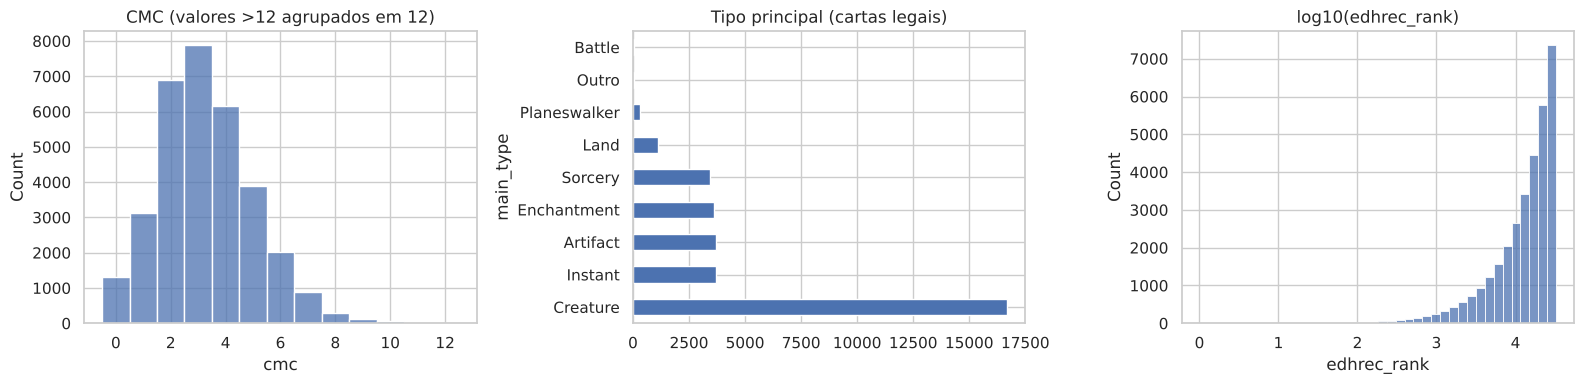

,count,mean,std,min,25%,50%,75%,max
cmc,32643.0,3.287964,1.747872,0.0,2.0,3.0,4.0,16.0
edhrec_rank,32575.0,16303.974735,9411.162674,1.0,8156.5,16300.0,24444.5,32710.0
n_ci,32643.0,1.128634,0.621660,0.0,1.0,1.0,1.0,5.0


In [10]:
legal = cards[cards.legal_commander == "legal"].copy()
legal["main_type"] = legal.type_line.fillna("").str.extract(
    r"(Creature|Land|Instant|Sorcery|Artifact|Enchantment|Planeswalker|Battle)", expand=False).fillna("Outro")
legal["n_ci"] = legal.color_identity.fillna("").str.len()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(legal.cmc.clip(upper=12), bins=13, discrete=True, ax=ax[0]); ax[0].set_title("CMC (valores >12 agrupados em 12)")
legal.main_type.value_counts().plot.barh(ax=ax[1]); ax[1].set_title("Tipo principal (cartas legais)")
sns.histplot(np.log10(legal.edhrec_rank.dropna()), bins=40, ax=ax[2]); ax[2].set_title("log10(edhrec_rank)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_cartas.png", dpi=150); plt.show()
legal[["cmc", "edhrec_rank", "n_ci"]].describe().T

In [11]:
outl = legal[legal.cmc >= 10][["name", "cmc", "type_line"]].sort_values("cmc", ascending=False)
print(f"{len(outl)} cartas com CMC >= 10 (outliers):"); outl.head(8)

95 cartas com CMC >= 10 (outliers):


,name,cmc,type_line
13335,Draco,16.0,Artifact Creature — Dragon
3486,Earthquake Dragon,15.0,Creature — Elemental Dragon
3379,Autochthon Wurm,15.0,Creature — Wurm
9471,Shadow of Mortality,15.0,Creature — Avatar
18648,Blinkmoth Infusion,14.0,Instant
10752,"Emrakul, the Promised End",13.0,Legendary Creature — Eldrazi
5837,Enter the Infinite,12.0,Sorcery
6954,"Emrakul, the World Anew",12.0,Legendary Creature — Eldrazi


**Outliers.** Há poucas cartas com CMC ≥ 10 (ex.: Draco, CMC 16; cartas "Un-" já foram filtradas pela legalidade).
São valores **legítimos** e raros, não erros, por isso não são removidos. Para reduzir sua influência em modelos
baseados em distância (k-NN) e na regressão logística, as features passam por `StandardScaler`, e também criamos
faixas de CMC no nível do deck (Seção 5). `edhrec_rank` é muito assimétrico (cauda até ~30 mil), então usamos
`log1p(edhrec_rank)`.

### 3.2 Decks Commander
Cada deck oficial tem 100 cartas: comandante(s) + 99. Antes de qualquer coisa verificamos **duplicatas**: o MTGJSON
lista reedições (ex.: versões *Collector's Edition*) com exatamente as mesmas cartas. Se o mesmo deck caísse no treino e
no teste, o modelo seria avaliado num deck que já viu, o que é vazamento. Removemos as cópias exatas e agrupamos decks
muito parecidos (Jaccard ≥ 0,5) no mesmo grupo de validação.

In [12]:
sizes = decks_raw.groupby("deck_id")["count"].sum()
print("cartas por deck:", sizes.describe()[["min", "max"]].to_dict())
print("decks com 2 comandantes (partner):", (decks_raw.groupby("deck_id").is_commander.sum() == 2).sum())
decks, groups = dedup_and_group(decks_raw, jaccard_threshold=0.5)
print(f"decks originais: {decks_raw.deck_id.nunique()} | após remover duplicatas exatas: {decks.deck_id.nunique()} "
      f"| grupos (Jaccard>=0.5): {groups.nunique()}")
decks_main = decks[decks.is_commander == 0].copy()
cards_by_id = cards.set_index("oracle_id")
cmd = decks[decks.is_commander == 1]
deck_ci = cmd.groupby("deck_id").oracle_id.apply(lambda s: "".join(c for c in "WUBRG" if c in "".join(cards_by_id.color_identity.reindex(s).fillna(""))))
card_ci = cards_by_id.color_identity.fillna("")
deck_meta = decks.drop_duplicates("deck_id").set_index("deck_id")[["deck_name", "release_date"]].assign(ci=deck_ci)
deck_meta.head()

cartas por deck: {'min': 100.0, 'max': 100.0}
decks com 2 comandantes (partner): 5


decks originais: 206 | após remover duplicatas exatas: 178 | grupos (Jaccard>=0.5): 178


,deck_name,release_date,ci
deck_id,,,
20WaysToWin_SLD,20 Ways to Win,2024-12-04,WUBRG
AbzanArmor_TDC,Abzan Armor,2025-04-11,WBG
AdaptiveEnchantment_C18,Adaptive Enchantment,2018-08-10,WUG
AhoyMateys_LCC,Ahoy Mateys,2023-11-17,UBR
AngelsTheyReJustLikeUsButCoolerAndWithWings_SLD,Angels: They're Just Like Us but Cooler and wi...,2023-08-14,W


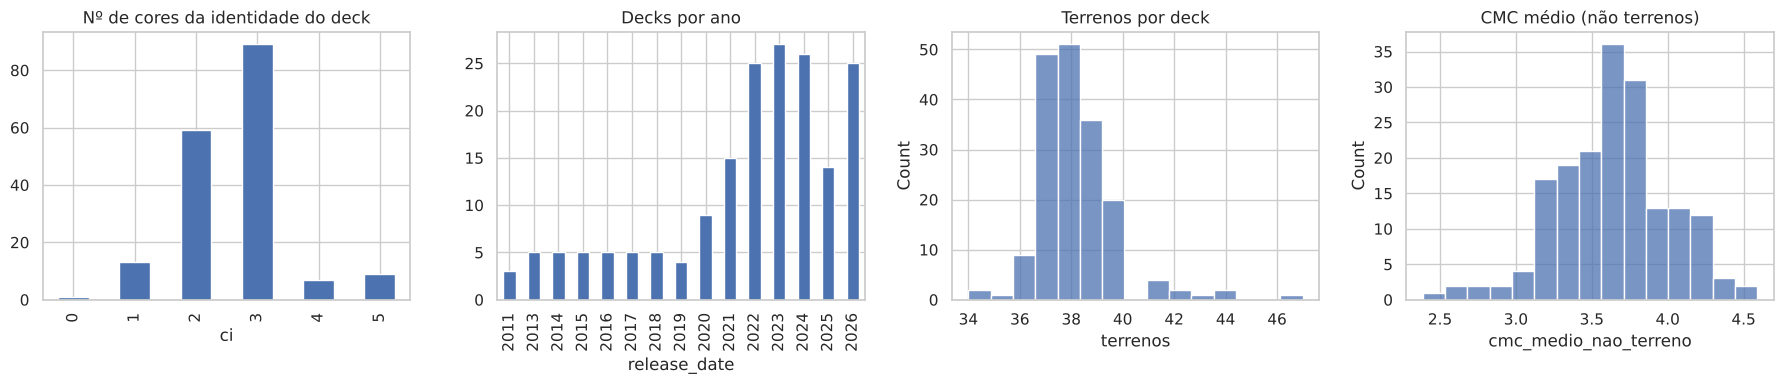

,count,mean,std,min,25%,50%,75%,max
terrenos,178.0,38.247191,1.641832,34.000000,37.000000,38.000000,39.000000,47.000000
criaturas,178.0,28.129213,5.892650,11.000000,25.000000,28.000000,31.750000,44.000000
cmc_medio_nao_terreno,178.0,3.638236,0.373990,2.387097,3.372488,3.666667,3.851209,4.590164


In [13]:
m = decks_main.merge(cards[["oracle_id", "cmc", "type_line"]], on="oracle_id")
m["is_land"] = m.type_line.str.contains("Land")
m["is_creature"] = m.type_line.str.contains("Creature")
per = m.groupby("deck_id").apply(lambda g: pd.Series({
    "terrenos": (g["count"] * g.is_land).sum(), "criaturas": (g["count"] * g.is_creature).sum(),
    "cmc_medio_nao_terreno": np.average(g.cmc[~g.is_land], weights=g["count"][~g.is_land])}), include_groups=False)
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
deck_meta.ci.str.len().value_counts().sort_index().plot.bar(ax=ax[0]); ax[0].set_title("Nº de cores da identidade do deck")
pd.to_datetime(deck_meta.release_date).dt.year.value_counts().sort_index().plot.bar(ax=ax[1]); ax[1].set_title("Decks por ano")
sns.histplot(per.terrenos, ax=ax[2], bins=15); ax[2].set_title("Terrenos por deck")
sns.histplot(per.cmc_medio_nao_terreno, ax=ax[3], bins=15); ax[3].set_title("CMC médio (não terrenos)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_decks.png", dpi=150); plt.show()
per.describe().T

cartas distintas nos decks: 6425 | presentes em 1 único deck: 68%


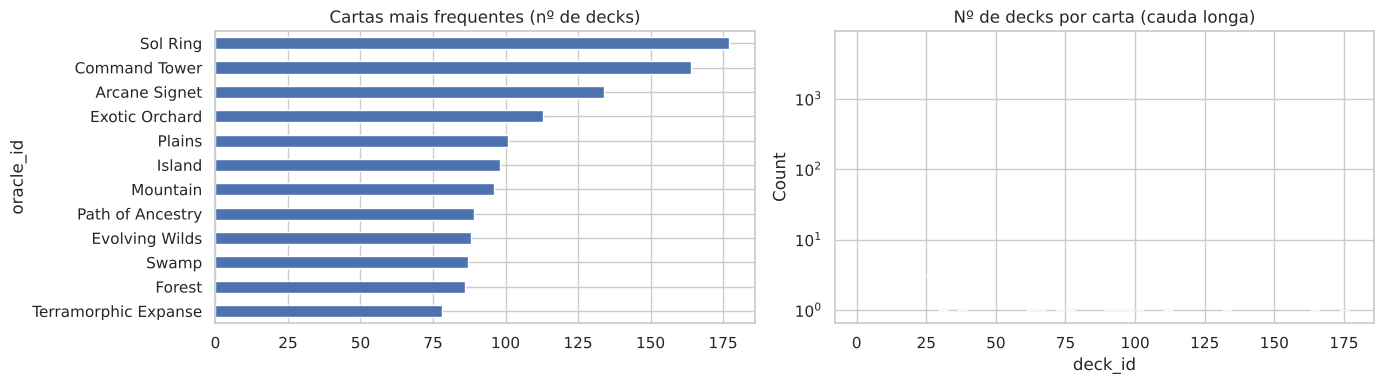

In [14]:
freq = decks_main.groupby("oracle_id").deck_id.nunique().sort_values(ascending=False)
top = freq.head(12).rename(index=cards_by_id.name)
print(f"cartas distintas nos decks: {len(freq)} | presentes em 1 único deck: {(freq == 1).mean():.0%}")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
top.sort_values().plot.barh(ax=ax[0]); ax[0].set_title("Cartas mais frequentes (nº de decks)")
sns.histplot(freq, bins=50, log_scale=(False, True), ax=ax[1]); ax[1].set_title("Nº de decks por carta (cauda longa)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_frequencia.png", dpi=150); plt.show()

**Achados da EDA que guiam decisões:**
- **Duplicatas de decks** existem e foram removidas (senão haveria vazamento entre treino e teste).
- Os decks seguem um **"esqueleto"** comum (~36–38 terrenos, ~30 criaturas, CMC médio ~3), e um núcleo de cartas
  aparece em quase todos (Sol Ring, Command Tower, Arcane Signet...). Por isso a **popularidade** é um preditor forte e
  é a base do nosso *baseline*. Mas ela precisa ser calculada **só com decks de treino** (Seção 6).
- A maioria das cartas aparece em **um único deck** (cauda longa): a popularidade não resolve tudo; as features de
  interação carta×deck precisam captar "encaixe".
- As identidades de cor são variadas (1 a 5 cores), então os negativos devem ser sorteados **dentro da identidade** de cada
  deck, senão a tarefa vira trivial ("a carta é de outra cor").

## 4. Rótulo e construção dos pares (deck, carta)
- **Positivos:** cartas distintas dos 99 de cada deck, exceto terrenos básicos (presença trivial) e o comandante.
- **Negativos difíceis:** para cada positivo sorteamos **3** cartas (proporção 1:3) que sejam: legais em Commander;
  dentro da identidade de cor do deck; ausentes do deck; do mesmo grupo terreno/não terreno; com |ΔCMC| ≤ 1; e,
  preferencialmente, com a mesma identidade de cor do positivo. Negativos aleatórios seriam fáceis demais (o modelo
  aprenderia só "cor errada" ou "custo absurdo").
- **Âncora:** cada negativo guarda o positivo para o qual foi sorteado (`anchor_id`). Na hora de calcular as features
  do deck, a âncora é retirada do deck **tanto para o positivo quanto para seus 3 negativos**. A situação simulada é a
  da aplicação: "o deck tem uma vaga aberta; qual candidata ocupava essa vaga?".

> **Por que a âncora importa (vazamento encontrado durante o desenvolvimento).** Na primeira versão, só os positivos
> tinham a própria carta removida do deck (98 cartas) e os negativos viam 99. A árvore de decisão aprendeu o rótulo
> pelo *denominador* das proporções do deck e alcançou F1 alto demais para a PR-AUC que tinha. Com a âncora, positivo e
> negativos compartilham exatamente o mesmo contexto de deck.

In [15]:
t0 = time.time()
pairs = make_pairs(decks, cards, deck_ci, neg_ratio=3, cmc_tol=1, seed=RANDOM_STATE)
print(f"pares: {len(pairs):,} | decks: {pairs.deck_id.nunique()} | positivos: {pairs.label.sum():,} "
      f"| taxa de positivos: {pairs.label.mean():.2%} | {time.time()-t0:.0f}s")

pares: 56,848 | decks: 178 | positivos: 14,212 | taxa de positivos: 25.00% | 64s


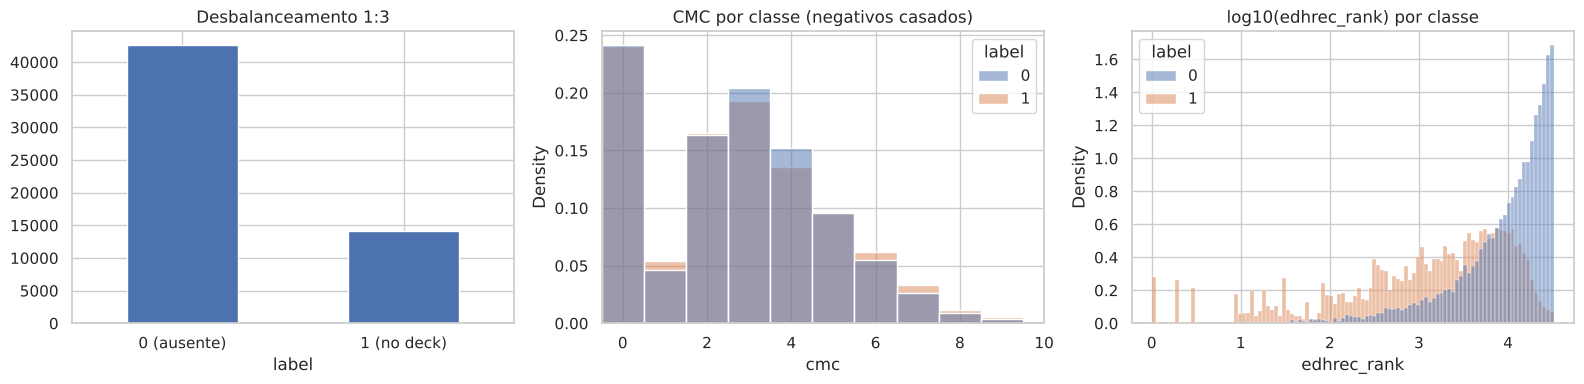

In [16]:
chk = pairs.merge(cards[["oracle_id", "cmc", "rarity", "edhrec_rank"]], on="oracle_id")
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
pairs.label.value_counts().rename({0: "0 (ausente)", 1: "1 (no deck)"}).plot.bar(ax=ax[0], rot=0); ax[0].set_title("Desbalanceamento 1:3")
sns.histplot(data=chk, x="cmc", hue="label", discrete=True, stat="density", common_norm=False, ax=ax[1]); ax[1].set_xlim(-0.5, 10); ax[1].set_title("CMC por classe (negativos casados)")
sns.histplot(data=chk, x=np.log10(chk.edhrec_rank), hue="label", stat="density", common_norm=False, ax=ax[2]); ax[2].set_title("log10(edhrec_rank) por classe")
plt.tight_layout(); plt.savefig(FIG_DIR / "pares_classes.png", dpi=150); plt.show()

Os negativos têm a **mesma distribuição de CMC** dos positivos: o sorteio "difícil" funcionou e o CMC sozinho não
separa as classes. Já o `edhrec_rank` separa bem (positivos são mais populares). Isso é esperado, mas também é um alerta:
o `edhrec_rank` é calculado pelo EDHREC a partir de decks de usuários, que **podem incluir listas inspiradas nesses
mesmos precons**. Essa é uma fonte externa de vazamento que não conseguimos eliminar, só **medir** (ablação na
Seção 10). Como a classe positiva é minoritária (25%), **acurácia não é a métrica principal**: usamos PR-AUC, ROC-AUC,
F1, precisão e revocação.

## 5. Engenharia de features
Todas as features abaixo são **determinísticas e não usam o rótulo**: dependem só do texto/atributos da carta e da
composição do deck (que, na aplicação, o usuário informa). Por isso podem ser calculadas antes da divisão sem vazamento.
A única feature que usa rótulos (popularidade nos decks de treino) é calculada **dentro do Pipeline**.

| Grupo | Features | Justificativa |
|---|---|---|
| Carta | `cmc`, `pip_W..G` (símbolos de mana por cor), `pip_generic`, `ci_W..G`, `n_ci` | custo e exigência de cor determinam se a carta é jogável no deck |
| Carta | `is_creature/instant/...`, `is_legendary` | decks têm proporções típicas por tipo |
| Carta | `power`, `toughness`, `loyalty` (+ indicador de ausência) | eficiência de criaturas/planeswalkers |
| Carta | `rarity` (ordinal), `n_keywords`, 15 palavras-chave binárias | raridade e habilidades evergreen indicam força/estilo |
| Carta | `role_*`: 12 papéis por regex no texto (ramp, compra, remoção, wipe, contra-mágica, tutor, tokens, recursão, proteção, ganho de vida, marcadores +1/+1, sacrifício) | todo deck Commander precisa de ramp/compra/remoção; versão leve e interpretável de "TF-IDF do texto" |
| Carta | `text_len`, `log_edhrec_rank` | complexidade; popularidade global externa (ver ablação) |
| Deck | `deck_mean_cmc`, `deck_cmcbin_*` (curva), `deck_pipshare_*` (distribuição de cores), `deck_frac_*` (tipos e papéis), `deck_n_ci` | contexto: o que o deck já tem |
| Interação | `int_pip_affinity` (símbolos da carta × cores do deck), `int_ci_fraction`, `int_ci_outside`, `int_cmc_diff`, `int_abs_cmc_diff` | encaixe de cor e de curva |
| Interação | `int_same_type_frac`, `int_same_role_frac`, `int_role_cosine` | a carta reforça o plano do deck? (similaridade de tags carta×deck) |
| Interação | `int_subtype_overlap` | sinergia tribal (ex.: Elfo num deck de Elfos) |
| Pipeline | `train_pop` | fração dos decks **de treino** compatíveis que usam a carta (leave-one-deck-out no treino) |

In [17]:
t0 = time.time()
cf = card_features(cards)
X_all = make_X(pairs, cf, decks_main, deck_ci, card_ci)
y_all = pairs.label.values
g_all = pairs.deck_id.map(groups).values
ID_COLS = ["deck_id", "oracle_id", "card_ci", "deck_ci"]
FEATS = [c for c in X_all.columns if c not in ID_COLS]
print(f"X: {X_all.shape} ({len(FEATS)} features + {len(ID_COLS)} colunas de identificação) | {time.time()-t0:.0f}s")
X_all[FEATS].describe().T.head(12)

X: (56848, 101) (97 features + 4 colunas de identificação) | 2s


,count,mean,std,min,25%,50%,75%,max
cmc,56848.0,2.731231,2.122361,0.0,1.0,3.0,4.0,13.0
pip_W,56848.0,0.214836,0.525013,0.0,0.0,0.0,0.0,8.0
ci_W,56848.0,0.235101,0.424065,0.0,0.0,0.0,0.0,1.0
pip_U,56848.0,0.193182,0.497190,0.0,0.0,0.0,0.0,5.0
ci_U,56848.0,0.216402,0.411795,0.0,0.0,0.0,0.0,1.0
pip_B,56848.0,0.191370,0.512051,0.0,0.0,0.0,0.0,6.0
ci_B,56848.0,0.205689,0.404208,0.0,0.0,0.0,0.0,1.0
pip_R,56848.0,0.174254,0.475920,0.0,0.0,0.0,0.0,5.0
ci_R,56848.0,0.196964,0.397708,0.0,0.0,0.0,0.0,1.0
pip_G,56848.0,0.214994,0.521097,0.0,0.0,0.0,0.0,8.0


,média y=0,média y=1,diferença padronizada
log_edhrec_rank,9.093,7.104,-1.119
text_len,157.924,153.545,-0.049
n_keywords,0.605,0.566,-0.047
int_pip_affinity,0.445,0.446,0.004
role_removal,0.083,0.086,0.011
int_abs_cmc_diff,1.862,1.931,0.052
role_ramp,0.246,0.294,0.109
role_draw,0.117,0.161,0.130
int_same_role_frac,0.151,0.192,0.212
int_role_cosine,0.266,0.348,0.237


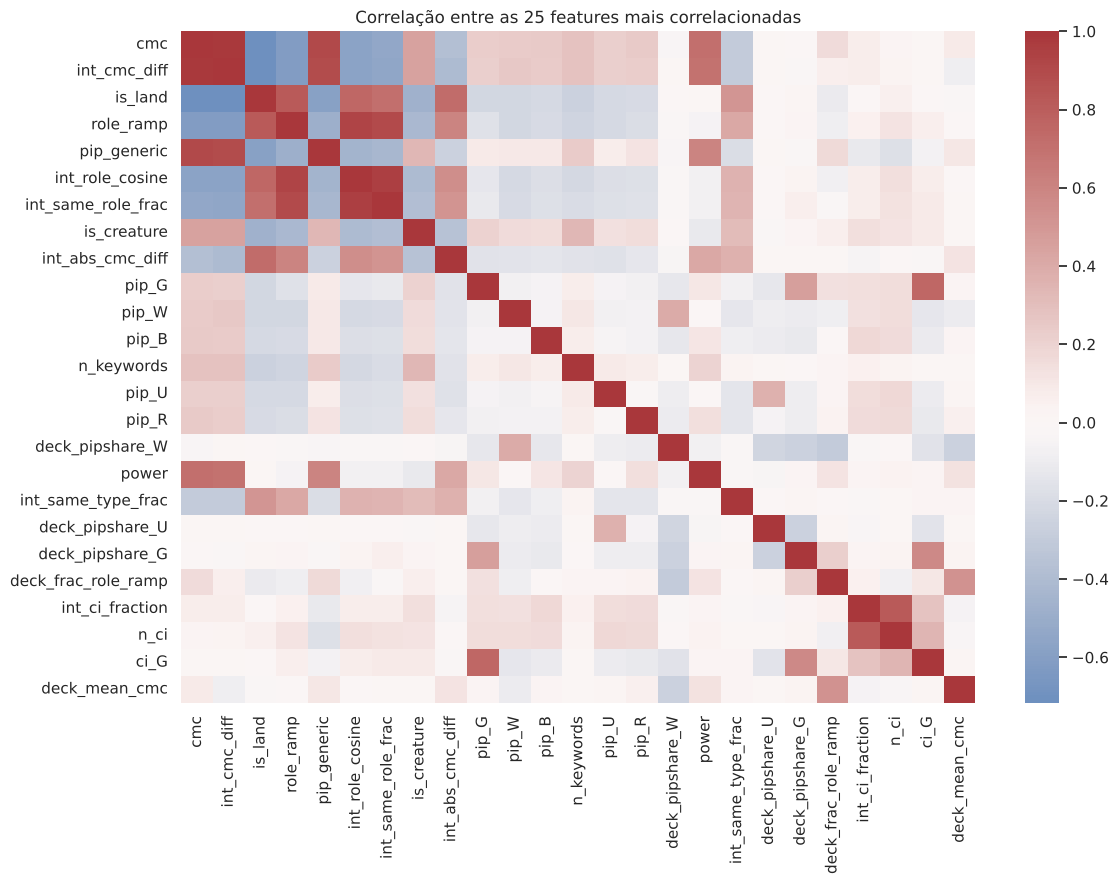

In [18]:
show = ["log_edhrec_rank", "rarity", "int_pip_affinity", "int_same_role_frac", "int_role_cosine",
        "int_subtype_overlap", "int_abs_cmc_diff", "role_ramp", "role_draw", "role_removal", "n_keywords", "text_len"]
summary = X_all[show].groupby(y_all).mean().T.rename(columns={0: "média y=0", 1: "média y=1"})
summary["diferença padronizada"] = (summary["média y=1"] - summary["média y=0"]) / X_all[show].std()
display(summary.sort_values("diferença padronizada").round(3))
num = X_all[FEATS].select_dtypes("number")
corr = num.loc[:, num.std() > 0].corr()
top_feats = corr.abs().sum().sort_values(ascending=False).head(25).index
plt.figure(figsize=(12, 9)); sns.heatmap(corr.loc[top_feats, top_feats], cmap="vlag", center=0)
plt.title("Correlação entre as 25 features mais correlacionadas"); plt.tight_layout(); plt.savefig(FIG_DIR / "correlacao.png", dpi=150); plt.show()

**Leitura.** Positivos são mais populares (menor `log_edhrec_rank`), mais raros, exercem papéis que o deck já usa
(`int_same_role_frac` e `int_role_cosine` maiores) e compartilham subtipos (tribal). Ramp e compra aparecem mais nos
positivos, o que é coerente com o "esqueleto" de Commander. A correlação mostra blocos esperados (ex.: `pip_X` × `ci_X`,
`power` × `toughness`, frações do deck entre si). São redundâncias que afetam o Naive Bayes (que supõe independência),
mas não a árvore e pouco a regressão logística regularizada.

## 6. Protocolo experimental e prevenção de vazamento
1. **Divisão por deck, não por linha.** `GroupShuffleSplit` separa 20% dos *grupos de decks* para **teste final**
   (nunca usados em seleção de modelo). A validação cruzada usa `GroupKFold(k=5, shuffle=True)` nos 80% restantes.
   Dividir por linha poria o mesmo deck no treino e no teste, e o modelo "decoraria" o deck.
2. **Tudo que é aprendido fica dentro do `Pipeline`**: popularidade de treino → imputação (mediana + indicador) →
   padronização → modelo. Logo, médias, desvios e popularidade são recalculados em cada fold só com dados de treino.
3. **Popularidade sem decks de teste**: `TrainPopularityEncoder` conta só os decks de treino; nas linhas de treino usa
   *leave-one-deck-out* para que a feature não contenha o rótulo da própria linha.
4. `random_state=42` em divisões, sorteio de negativos e modelos.

In [19]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_idx, te_idx = next(gss.split(X_all, y_all, groups=g_all))
X_tr, X_te, y_tr, y_te = X_all.iloc[tr_idx], X_all.iloc[te_idx], y_all[tr_idx], y_all[te_idx]
g_tr = g_all[tr_idx]
assert set(g_all[tr_idx]).isdisjoint(g_all[te_idx]), "deck no treino e no teste!"
print(f"treino: {len(X_tr):,} linhas / {len(set(g_tr))} decks | teste: {len(X_te):,} linhas / {len(set(g_all[te_idx]))} decks")
print(f"taxa de positivos treino={y_tr.mean():.3f} teste={y_te.mean():.3f}")

def make_pipeline(model, columns=None):
    # columns=None -> todas as features; senão, mantém só as colunas listadas (após a popularidade)
    return Pipeline([("pop", TrainPopularityEncoder()), ("select", ColumnSelector(columns)),
                     ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                     ("scale", StandardScaler()), ("model", model)])

cv = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "f1": "f1", "precision": "precision",
           "recall": "recall", "accuracy": "accuracy"}

treino: 45,668 linhas / 142 decks | teste: 11,180 linhas / 36 decks
taxa de positivos treino=0.250 teste=0.250


## 7. Etapa 1: baseline e primeiro modelo (regressão logística)
**Baselines (referência mínima):**
- *Classe majoritária* (`DummyClassifier`): mostra por que acurácia engana (≈75% sem aprender nada).
- *Popularidade global* (opção B do planejamento): regressão logística usando **apenas** `log_edhrec_rank`, ou seja,
  "sugira as cartas mais populares". Qualquer modelo útil precisa superar esse ranking.

**Primeiro modelo:** regressão logística com todas as features. Linear, rápida e interpretável (coeficientes).

In [20]:
def evaluate(model, X, y, name):
    proba = model.predict_proba(X)[:, 1]; pred = (proba >= 0.5).astype(int)
    return {"modelo": name, "PR-AUC": average_precision_score(y, proba), "ROC-AUC": roc_auc_score(y, proba),
            "F1": f1_score(y, pred, zero_division=0), "precisão": precision_score(y, pred, zero_division=0),
            "revocação": recall_score(y, pred), "acurácia": accuracy_score(y, pred)}

etapa1 = {
    "Baseline: classe majoritária": make_pipeline(DummyClassifier(strategy="most_frequent")),
    "Baseline: popularidade (edhrec_rank)": make_pipeline(LogisticRegression(), columns=["log_edhrec_rank"]),
    "Regressão logística (todas)": make_pipeline(LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
}
rows = []
for name, pipe in etapa1.items():
    pipe.fit(X_tr, y_tr); rows.append(evaluate(pipe, X_te, y_te, name))
pd.DataFrame(rows).set_index("modelo").round(3)

,PR-AUC,ROC-AUC,F1,precisão,revocação,acurácia
modelo,,,,,,
Baseline: classe majoritária,0.250,0.500,0.000,0.000,0.000,0.750
Baseline: popularidade (edhrec_rank),0.606,0.818,0.440,0.661,0.330,0.790
Regressão logística (todas),0.740,0.872,0.634,0.773,0.537,0.845


Interpretação (treino/teste simples, por deck): a classe majoritária tem acurácia ~0,75 e F1 = 0, a prova de que
acurácia é inadequada aqui. A popularidade sozinha já ordena bem as cartas (ROC-AUC alto). A regressão logística com
todas as features deve superá-la em PR-AUC; o quanto supera mede o valor das features de deck e interação. Os números
definitivos vêm da validação cruzada (Seção 8), que é menos sensível a um único sorteio de decks.

## 8. Comparação de modelos com validação cruzada agrupada (k=5)
Modelos: **3+ clássicos vistos em aula** (regressão logística, árvore de decisão, k-NN, Naive Bayes) + **MLP**, mais os
baselines. Cada modelo tem uma grade pequena de hiperparâmetros escolhida por `GridSearchCV` com o **mesmo**
`GroupKFold(5)` (critério: PR-AUC). Reportamos média ± desvio-padrão nos 5 folds para a melhor configuração.

| Modelo | Hiperparâmetros explorados | Por quê |
|---|---|---|
| Regressão logística | `C` ∈ {0,01; 0,1; 1; 10}, `class_weight` ∈ {None, balanced} | regularização; peso de classe para o desbalanceamento |
| Árvore de decisão | `max_depth` ∈ {4, 6, 8, 12}, `min_samples_leaf` ∈ {20, 100}, `class_weight` | controle de sobreajuste |
| k-NN | `n_neighbors` ∈ {15, 51, 101}, `weights` ∈ {uniform, distance} | vizinhanças maiores suavizam ruído |
| Naive Bayes (Gaussiano) | `var_smoothing` ∈ {1e-9, 1e-6, 1e-3} | estabilidade numérica |
| MLP | `hidden_layer_sizes` ∈ {(64,), (64, 32)}, `alpha` ∈ {1e-4, 1e-2}; `early_stopping` | capacidade × regularização |

Random Forest **não** é usado (não visto em aula / sem confirmação do professor). SVM ficou fora por custo
(kernel RBF é O(n²) com ~45 mil linhas) e prazo.

In [21]:
models = {
    "Regressão logística": (LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
                            {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]}),
    "Árvore de decisão": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                          {"model__max_depth": [4, 6, 8, 12], "model__min_samples_leaf": [20, 100], "model__class_weight": [None, "balanced"]}),
    "k-NN": (KNeighborsClassifier(), {"model__n_neighbors": [15, 51, 101], "model__weights": ["uniform", "distance"]}),
    "Naive Bayes": (GaussianNB(), {"model__var_smoothing": [1e-9, 1e-6, 1e-3]}),
    "MLP": (MLPClassifier(early_stopping=True, max_iter=300, random_state=RANDOM_STATE),
            {"model__hidden_layer_sizes": [(64,), (64, 32)], "model__alpha": [1e-4, 1e-2]}),
}
searches, cv_rows = {}, []
for name, (est, grid) in models.items():
    t0 = time.time()
    gs = GridSearchCV(make_pipeline(est), grid, scoring=SCORING, refit="pr_auc", cv=cv, n_jobs=-1)
    gs.fit(X_tr, y_tr, groups=g_tr)
    searches[name] = gs
    i = gs.best_index_; r = gs.cv_results_
    row = {"modelo": name, "melhores hiperparâmetros": {k.replace("model__", ""): v for k, v in gs.best_params_.items()},
           "tempo médio de treino (s)": r["mean_fit_time"][i]}
    for k in SCORING:
        row[k] = f'{r[f"mean_test_{k}"][i]:.3f} ± {r[f"std_test_{k}"][i]:.3f}'
        row["_" + k] = r[f"mean_test_{k}"][i]
    cv_rows.append(row); print(f"{name}: {time.time()-t0:.0f}s")

for name, pipe in [("Baseline: classe majoritária", etapa1["Baseline: classe majoritária"]),
                   ("Baseline: popularidade (edhrec_rank)", etapa1["Baseline: popularidade (edhrec_rank)"])]:
    r = cross_validate(pipe, X_tr, y_tr, groups=g_tr, cv=cv, scoring=SCORING, n_jobs=-1)
    row = {"modelo": name, "melhores hiperparâmetros": "-", "tempo médio de treino (s)": r["fit_time"].mean()}
    for k in SCORING:
        row[k] = f'{r[f"test_{k}"].mean():.3f} ± {r[f"test_{k}"].std():.3f}'; row["_" + k] = r[f"test_{k}"].mean()
    cv_rows.append(row)
cv_table = pd.DataFrame(cv_rows).set_index("modelo").sort_values("_pr_auc", ascending=False)
cv_table.to_csv(FIG_DIR / "tabela_cv.csv")
cv_table[["pr_auc", "roc_auc", "f1", "precision", "recall", "accuracy", "tempo médio de treino (s)", "melhores hiperparâmetros"]]

Regressão logística: 13s


Árvore de decisão: 32s


k-NN: 45s


Naive Bayes: 4s


MLP: 31s


,pr_auc,roc_auc,f1,precision,recall,accuracy,tempo médio de treino (s),melhores hiperparâmetros
modelo,,,,,,,,
MLP,0.761 ± 0.012,0.886 ± 0.006,0.658 ± 0.014,0.752 ± 0.017,0.586 ± 0.028,0.848 ± 0.003,3.514576,"{'alpha': 0.01, 'hidden_layer_sizes': (64,)}"
Regressão logística,0.743 ± 0.009,0.874 ± 0.007,0.627 ± 0.007,0.765 ± 0.006,0.531 ± 0.011,0.842 ± 0.002,0.827922,"{'C': 1, 'class_weight': None}"
Árvore de decisão,0.729 ± 0.012,0.869 ± 0.008,0.651 ± 0.007,0.563 ± 0.008,0.772 ± 0.016,0.793 ± 0.004,1.685931,"{'class_weight': 'balanced', 'max_depth': 12, ..."
k-NN,0.657 ± 0.010,0.810 ± 0.007,0.475 ± 0.021,0.798 ± 0.011,0.339 ± 0.023,0.813 ± 0.004,0.537929,"{'n_neighbors': 15, 'weights': 'distance'}"
Baseline: popularidade (edhrec_rank),0.604 ± 0.013,0.807 ± 0.015,0.454 ± 0.010,0.661 ± 0.018,0.346 ± 0.010,0.792 ± 0.004,0.169019,-
Naive Bayes,0.570 ± 0.018,0.746 ± 0.017,0.413 ± 0.005,0.267 ± 0.002,0.919 ± 0.019,0.347 ± 0.003,0.506356,{'var_smoothing': 0.001}
Baseline: classe majoritária,0.250 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.750 ± 0.000,0.483081,-


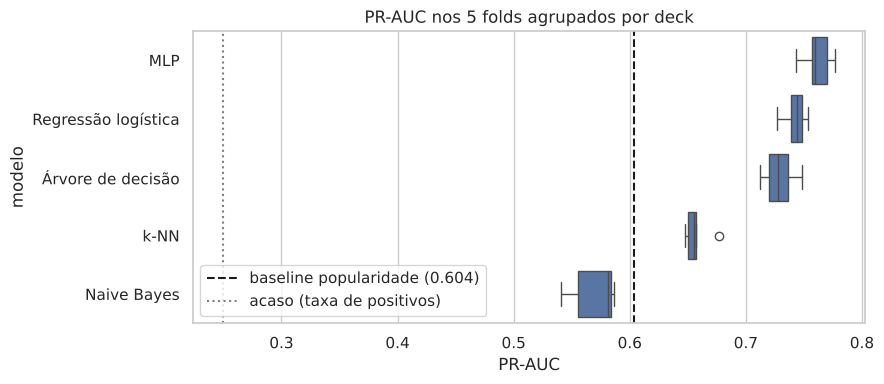

In [22]:
long = []
for name, gs in searches.items():
    i = gs.best_index_
    for f in range(5):
        long.append({"modelo": name, "PR-AUC": gs.cv_results_[f"split{f}_test_pr_auc"][i]})
long = pd.DataFrame(long)
plt.figure(figsize=(9, 4))
sns.boxplot(data=long, x="PR-AUC", y="modelo", order=long.groupby("modelo")["PR-AUC"].mean().sort_values(ascending=False).index)
pop_cv = cv_table.loc["Baseline: popularidade (edhrec_rank)", "_pr_auc"]
plt.axvline(pop_cv, ls="--", c="k", label=f"baseline popularidade ({pop_cv:.3f})"); plt.axvline(0.25, ls=":", c="gray", label="acaso (taxa de positivos)")
plt.legend(loc="lower left"); plt.title("PR-AUC nos 5 folds agrupados por deck"); plt.tight_layout()
plt.savefig(FIG_DIR / "cv_boxplot.png", dpi=150); plt.show()

In [23]:
# Sensibilidade a hiperparâmetros: variação de PR-AUC média entre as configurações da grade
sens = pd.DataFrame([{"modelo": n, "PR-AUC mínima na grade": gs.cv_results_["mean_test_pr_auc"].min(),
                      "PR-AUC máxima na grade": gs.cv_results_["mean_test_pr_auc"].max()} for n, gs in searches.items()])
sens["amplitude"] = sens["PR-AUC máxima na grade"] - sens["PR-AUC mínima na grade"]
sens.set_index("modelo").round(3)

,PR-AUC mínima na grade,PR-AUC máxima na grade,amplitude
modelo,,,
Regressão logística,0.735,0.743,0.007
Árvore de decisão,0.654,0.729,0.075
k-NN,0.624,0.657,0.034
Naive Bayes,0.544,0.570,0.025
MLP,0.748,0.761,0.013


## 9. Avaliação no conjunto de teste (decks nunca vistos)
Cada melhor configuração é re-treinada em todo o treino e avaliada uma única vez nos decks de teste.

**Métrica de aplicação: top-k recall.** Para cada deck de teste e cada carta real escondida (positivo), ordenamos
essa carta junto com **todos os negativos do mesmo deck**; acerto se ela ficar entre as *k* melhores. Isso simula "o
usuário pergunta o que falta no deck e o app sugere *k* cartas". Comparamos com o acaso, que é *k*/(nº de candidatas).

In [24]:
best_models = {n: gs.best_estimator_ for n, gs in searches.items()}
best_models["Baseline: popularidade (edhrec_rank)"] = etapa1["Baseline: popularidade (edhrec_rank)"]
test_proba = {n: m.predict_proba(X_te)[:, 1] for n, m in best_models.items()}

def topk_recall(proba, y, decks_ids, k=10):
    df = pd.DataFrame({"p": proba, "y": y, "d": decks_ids}); hits = []; chance = []
    for _, g in df.groupby("d"):
        negs = np.sort(g.p[g.y == 0].values)[::-1]
        for p in g.p[g.y == 1]:
            rank = 1 + np.searchsorted(-negs, -p, side="left")  # nº de negativos com score maior + 1
            hits.append(rank <= k); chance.append(min(k / (len(negs) + 1), 1))
    return np.mean(hits), np.mean(chance)

deck_te = X_te.deck_id.values
rows = []
for n, p in test_proba.items():
    r = evaluate(best_models[n], X_te, y_te, n)
    for k in (1, 10, 25):
        r[f"top-{k} recall"], ch = topk_recall(p, y_te, deck_te, k); r[f"acaso top-{k}"] = ch
    rows.append(r)
test_table = pd.DataFrame(rows).set_index("modelo").sort_values("PR-AUC", ascending=False)
test_table.round(3).to_csv(FIG_DIR / "tabela_teste.csv")
test_table.round(3)

,PR-AUC,ROC-AUC,F1,precisão,revocação,acurácia,top-1 recall,acaso top-1,top-10 recall,acaso top-10,top-25 recall,acaso top-25
modelo,,,,,,,,,,,,
MLP,0.763,0.888,0.673,0.743,0.615,0.850,0.195,0.004,0.522,0.043,0.694,0.107
Árvore de decisão,0.741,0.877,0.662,0.568,0.794,0.797,0.160,0.004,0.503,0.043,0.679,0.107
Regressão logística,0.740,0.872,0.634,0.773,0.537,0.845,0.170,0.004,0.486,0.043,0.664,0.107
k-NN,0.660,0.812,0.476,0.785,0.342,0.812,0.140,0.004,0.396,0.043,0.550,0.107
Baseline: popularidade (edhrec_rank),0.606,0.818,0.440,0.661,0.330,0.790,0.097,0.004,0.282,0.043,0.471,0.107
Naive Bayes,0.559,0.743,0.415,0.268,0.914,0.355,0.169,0.004,0.303,0.043,0.469,0.107


Melhor modelo pela PR-AUC da validação cruzada: MLP


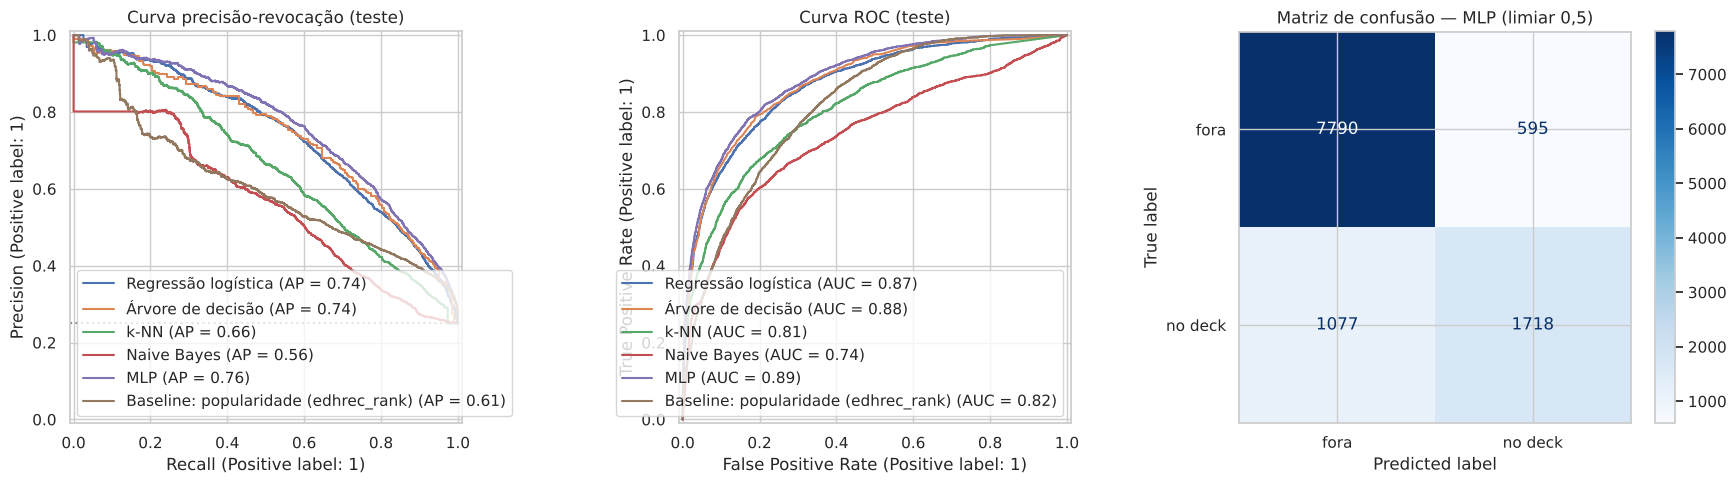

In [25]:
best_name = cv_table.drop(index=[i for i in cv_table.index if i.startswith("Baseline")])["_pr_auc"].idxmax()
print("Melhor modelo pela PR-AUC da validação cruzada:", best_name)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for n, p in test_proba.items():
    PrecisionRecallDisplay.from_predictions(y_te, p, name=n, ax=ax[0])
    RocCurveDisplay.from_predictions(y_te, p, name=n, ax=ax[1])
ax[0].axhline(y_te.mean(), ls=":", c="gray"); ax[0].set_title("Curva precisão-revocação (teste)"); ax[1].set_title("Curva ROC (teste)")
ConfusionMatrixDisplay.from_predictions(y_te, (test_proba[best_name] >= 0.5).astype(int), ax=ax[2],
                                        display_labels=["fora", "no deck"], cmap="Blues")
ax[2].set_title(f"Matriz de confusão — {best_name} (limiar 0,5)")
plt.tight_layout(); plt.savefig(FIG_DIR / "teste_curvas_confusao.png", dpi=150); plt.show()

## 10. Importância de features e ablação da popularidade
- **Importância por permutação** (no conjunto de teste) para o melhor modelo: quanto a PR-AUC cai ao embaralhar cada
  feature. Vale para qualquer modelo, inclusive a MLP.
- **Ablação:** re-treinamos o melhor modelo **sem** `log_edhrec_rank` (popularidade externa, potencialmente
  contaminada pelos próprios precons) e **sem** `train_pop`, para medir quanto do resultado depende de popularidade e
  quanto vem do "encaixe" carta×deck.

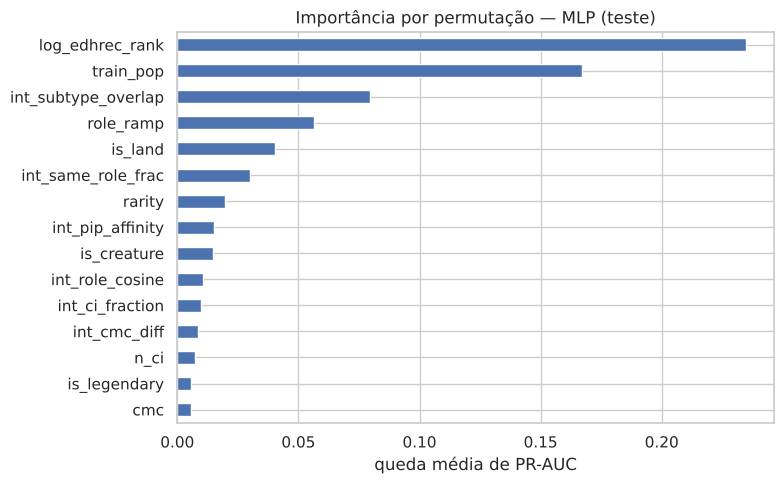

In [26]:
from sklearn.inspection import permutation_importance
best = best_models[best_name]
# a permutação é feita após o encoder de popularidade, sobre a matriz de features já com train_pop
Xt_te = best.named_steps["pop"].transform(X_te)
rest = Pipeline(best.steps[1:])
pi = permutation_importance(rest, Xt_te, y_te, scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xt_te.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5)); imp.sort_values().plot.barh(); plt.xlabel("queda média de PR-AUC")
plt.title(f"Importância por permutação — {best_name} (teste)"); plt.tight_layout(); plt.savefig(FIG_DIR / "importancia.png", dpi=150); plt.show()

In [27]:
lr_best = best_models["Regressão logística"]
coef = pd.Series(lr_best.named_steps["model"].coef_[0],
                 index=lr_best.named_steps["impute"].get_feature_names_out(Xt_te.columns))
print("Regressão logística: maiores coeficientes (features padronizadas)")
pd.concat([coef.sort_values().head(8), coef.sort_values().tail(8)]).round(3).to_frame("coef")

Regressão logística: maiores coeficientes (features padronizadas)


,coef
log_edhrec_rank,-1.305
role_ramp,-1.098
is_land,-0.878
is_creature,-0.640
pip_generic,-0.417
missingindicator_int_pip_affinity,-0.315
missingindicator_toughness,-0.277
missingindicator_log_edhrec_rank,-0.236
int_ci_fraction,0.266
missingindicator_power,0.278


In [28]:
abl_rows = []
all_cols = list(best.named_steps["pop"].transform(X_tr.head(5)).columns)
variants = {"todas as features": None,
            "sem log_edhrec_rank": [c for c in all_cols if c != "log_edhrec_rank"],
            "sem train_pop": [c for c in all_cols if c != "train_pop"],
            "sem nenhuma popularidade": [c for c in all_cols if c not in ("log_edhrec_rank", "train_pop")]}
best_est = best.named_steps["model"]
for v, cols in variants.items():
    from sklearn.base import clone
    pipe = make_pipeline(clone(best_est), columns=cols)
    r = cross_validate(pipe, X_tr, y_tr, groups=g_tr, cv=cv, scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"}, n_jobs=-1)
    abl_rows.append({"variante": v, "PR-AUC (CV)": f'{r["test_pr_auc"].mean():.3f} ± {r["test_pr_auc"].std():.3f}',
                     "ROC-AUC (CV)": f'{r["test_roc_auc"].mean():.3f} ± {r["test_roc_auc"].std():.3f}'})
pd.DataFrame(abl_rows).set_index("variante")

,PR-AUC (CV),ROC-AUC (CV)
variante,,
todas as features,0.761 ± 0.012,0.886 ± 0.006
sem log_edhrec_rank,0.725 ± 0.009,0.856 ± 0.006
sem train_pop,0.739 ± 0.014,0.877 ± 0.008
sem nenhuma popularidade,0.557 ± 0.012,0.772 ± 0.010


## 11. Regra de remoção e teste prático
**Regra:** score(c) = p(c pertence ao deck). Dada a candidata *C* e o deck *D*:
calcula-se score(*x*) para cada *x* ∈ *D*, excluindo terrenos básicos, o comandante e cartas travadas pelo usuário.
Cada *x* é avaliado com o deck **sem ele mesmo** (mesma situação do treino). Seja pior = argmin score(*x*):
se score(*C*) > score(pior) + δ → "Melhora o deck. Remova: pior"; senão → "Não melhora".

**Teste prático (decks de teste, nunca vistos):** em cada deck retiramos uma carta não-terreno real *r* e colocamos um
**intruso** *i*, de dois tipos: (a) **fora da identidade de cor** do deck; (b) **dentro da cor**, carta legal
qualquer ausente do deck (intruso mais sutil). Medimos:
1. **Detecção do intruso:** taxa de vezes em que o pior do deck é o intruso (top-1) ou está entre os 5 piores
   (top-5), comparada ao acaso.
2. **Decisão de troca com δ:** oferecer *r* de volta ao deck com intruso deveria resultar em "Melhora" (positivo);
   oferecer uma carta aleatória dentro da cor ao deck original deveria resultar em "Não melhora" (negativo).

**Escolha de δ:** feita **sem tocar nos decks de teste**. Separamos 20% dos grupos de treino como validação,
re-treinamos o melhor modelo nos 80% restantes, simulamos as trocas na validação e escolhemos o δ que maximiza a
acurácia balanceada da decisão. Um δ > 0 exige margem mínima antes de recomendar uma troca, porque uma troca tem custo
real para o usuário e o score tem ruído.

δ escolhido na validação: 0.1


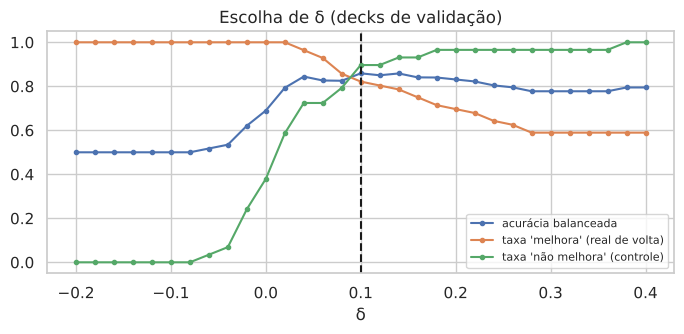

In [29]:
from sklearn.base import clone
legal_nonland = cards[(cards.legal_commander == "legal") & ~cards.type_line.fillna("").str.contains("Land")].copy()
legal_nonland["ci"] = legal_nonland.color_identity.fillna("")
is_land = cf["is_land"]

def simulate(model, deck_ids, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    mods, info, cand_rows = [], [], []
    for d in deck_ids:
        dm = decks_main[decks_main.deck_id == d]
        ci_d = set(deck_ci[d]); in_deck = set(dm.oracle_id)
        members = [o for o in dm.oracle_id.unique() if is_land.get(o, 1) == 0]
        r = members[rng.integers(len(members))]
        inside = legal_nonland[legal_nonland.ci.map(lambda s: set(s) <= ci_d) & ~legal_nonland.oracle_id.isin(in_deck)]
        outside = legal_nonland[~legal_nonland.ci.map(lambda s: set(s) <= ci_d)]
        control = inside.oracle_id.values[rng.integers(len(inside))]
        cand_rows.append({"deck_id": d, "oracle_id": control, "kind": "controle"})
        for kind, pool in (("fora_da_cor", outside), ("dentro_da_cor", inside)):
            if len(pool) == 0: continue  # deck de 5 cores não tem intruso "fora da cor"
            i = pool.oracle_id.values[rng.integers(len(pool))]
            nd = f"{d}__{kind}"
            mod = pd.concat([dm[dm.oracle_id != r], pd.DataFrame({"deck_id": [d], "oracle_id": [i], "count": [1]})]).assign(deck_id=nd)
            mods.append(mod); info.append({"deck": nd, "orig": d, "kind": kind, "removed": r, "intruder": i})
            cand_rows.append({"deck_id": nd, "oracle_id": r, "kind": "real_de_volta"})
    mods = pd.concat(mods); info = pd.DataFrame(info)
    dci = pd.concat([deck_ci, pd.Series({row.deck: deck_ci[row.orig] for row in info.itertuples()})])
    all_decks = pd.concat([decks_main[decks_main.deck_id.isin(deck_ids)], mods])
    members_sc = score_members(model, cf, all_decks, dci, card_ci)
    cands = pd.DataFrame(cand_rows)
    cands["score"] = score_candidates(model, cf, all_decks, dci, card_ci, cands)
    worst = members_sc.loc[members_sc.groupby("deck_id").score.idxmin()].set_index("deck_id")
    ranks = members_sc.assign(r=members_sc.groupby("deck_id").score.rank(method="first")).set_index(["deck_id", "oracle_id"]).r
    info["rank_intruso"] = [ranks[(row.deck, row.intruder)] for row in info.itertuples()]
    info["n_avaliadas"] = info.deck.map(members_sc.groupby("deck_id").size())
    cands["pior_score"] = cands.deck_id.map(worst.score)
    return info, cands

def decide(cands, delta):
    improves = cands.score > cands.pior_score + delta
    should = cands.kind == "real_de_volta"
    tpr = improves[should].mean(); tnr = (~improves[~should]).mean()
    return (tpr + tnr) / 2, tpr, tnr

# --- escolha de delta: validação dentro do treino ---
inner = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
fit_i, val_i = next(inner.split(X_tr, y_tr, groups=g_tr))
model_fit = clone(best).fit(X_tr.iloc[fit_i], y_tr[fit_i])
val_decks = sorted(set(X_tr.deck_id.values[val_i]))
_, cands_val = simulate(model_fit, val_decks)
deltas = np.round(np.arange(-0.2, 0.41, 0.02), 2)
dres = pd.DataFrame([dict(zip(["delta", "acurácia balanceada", "taxa 'melhora' (real de volta)", "taxa 'não melhora' (controle)"], (d, *decide(cands_val, d)))) for d in deltas])
DELTA = float(dres.loc[dres["acurácia balanceada"].idxmax(), "delta"])
print(f"δ escolhido na validação: {DELTA}")
plt.figure(figsize=(7, 3.5)); plt.plot(dres.delta, dres.iloc[:, 1:], marker="o", ms=3); plt.legend(dres.columns[1:], fontsize=8)
plt.axvline(DELTA, ls="--", c="k"); plt.xlabel("δ"); plt.title("Escolha de δ (decks de validação)"); plt.tight_layout()
plt.savefig(FIG_DIR / "delta.png", dpi=150); plt.show()

In [30]:
test_decks = sorted(set(deck_te))
info_te, cands_te = simulate(best, test_decks)
rows = []
for kind, g in info_te.groupby("kind"):
    rows.append({"intruso": kind, "decks": len(g), "intruso = pior (top-1)": (g.rank_intruso == 1).mean(),
                 "intruso entre 5 piores": (g.rank_intruso <= 5).mean(),
                 "acaso top-1": (1 / g.n_avaliadas).mean(), "acaso top-5": (5 / g.n_avaliadas).mean(),
                 "posição mediana do intruso": g.rank_intruso.median()})
display(pd.DataFrame(rows).set_index("intruso").round(3))
ba, tpr, tnr = decide(cands_te, DELTA)
print(f"Decisão com δ={DELTA} nos decks de teste: acurácia balanceada={ba:.3f} | "
      f"'melhora' quando a carta real volta={tpr:.3f} | 'não melhora' para carta aleatória={tnr:.3f}")

,decks,intruso = pior (top-1),intruso entre 5 piores,acaso top-1,acaso top-5,posição mediana do intruso
intruso,,,,,,
dentro_da_cor,36,0.361,0.583,0.013,0.065,3.0
fora_da_cor,33,0.273,0.485,0.013,0.065,7.0


Decisão com δ=0.1 nos decks de teste: acurácia balanceada=0.815 | 'melhora' quando a carta real volta=0.768 | 'não melhora' para carta aleatória=0.861


**Leitura do teste prático.** O intruso *fora da cor* é, de forma contraintuitiva, detectado **pior** que o intruso
*dentro da cor*. A explicação vem dos dados: por construção, **nenhuma** linha de treino tem carta fora da identidade
do deck (positivos são legais e negativos foram sorteados dentro da cor). As features `int_ci_outside` e
`int_ci_fraction` ficam constantes ou quase constantes no treino, e o modelo nunca aprendeu o que fazer com elas. É um
caso clássico de **entrada fora da distribuição**. Em Commander uma carta fora da identidade é **ilegal**, então isso
não deve ser decidido por ML: no backend aplicamos uma **regra determinística de legalidade antes do modelo** (carta
ilegal → "não pode entrar"; carta ilegal já no deck → é a primeira a sair). O ML fica para o que é de fato incerto:
escolher entre cartas legais.

In [31]:
# Exemplo legível de recomendação (primeiro deck de teste, intruso dentro da cor)
ex = info_te[info_te.kind == "dentro_da_cor"].iloc[0]
c = cands_te[(cands_te.deck_id == ex.deck)].iloc[0]
print(f"Deck: {deck_meta.deck_name[ex.orig]} | intruso: {cf.name[ex.intruder]} | carta real removida: {cf.name[ex.removed]}")
print(f"score(candidata '{cf.name[c.oracle_id]}') = {c.score:.3f} | score(pior) = {c.pior_score:.3f} | δ = {DELTA}")
print("→", "Melhora o deck." if c.score > c.pior_score + DELTA else "Não melhora.")

Deck: Aura of Courage | intruso: Sword Coast Sailor | carta real removida: Cold-Eyed Selkie
score(candidata 'Cold-Eyed Selkie') = 0.627 | score(pior) = 0.003 | δ = 0.1
→ Melhora o deck.


## 12. Exportação do modelo
O melhor modelo (pela PR-AUC na validação cruzada) é re-treinado com **todos** os decks (treino + teste), já que a
avaliação terminou, e exportado com `joblib` junto com δ e metadados. O backend (`backend-ml/`) carrega este arquivo e
usa o mesmo pacote `manatrade_ml` para montar as features.

In [32]:
import joblib, json
final = clone(best).fit(X_all, y_all)
OUT = Path("../models") if Path("../models").exists() else Path("models"); OUT.mkdir(exist_ok=True)
bundle = {"pipeline": final, "delta": DELTA, "model_name": best_name, "sklearn_version": sklearn.__version__,
          "features": FEATS, "n_decks_train": int(pairs.deck_id.nunique()), "random_state": RANDOM_STATE}
joblib.dump(bundle, OUT / "best_model.joblib", compress=3)
meta = {k: v for k, v in bundle.items() if k not in ("pipeline", "features")}
meta["cv_pr_auc"] = float(cv_table.loc[best_name, "_pr_auc"]); meta["test_pr_auc"] = float(test_table.loc[best_name, "PR-AUC"])
(OUT / "model_meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))
print(OUT / "best_model.joblib", f"{(OUT / 'best_model.joblib').stat().st_size/1e6:.1f} MB"); meta

../models/best_model.joblib 0.4 MB


{'delta': 0.1,
 'model_name': 'MLP',
 'sklearn_version': '1.9.1',
 'n_decks_train': 178,
 'random_state': 42,
 'cv_pr_auc': 0.7610813053213403,
 'test_pr_auc': 0.762995970281668}

## 13. Análise crítica, limitações e próximos passos
> As afirmações abaixo devem ser conferidas contra as tabelas geradas acima a cada execução. A redação final do
> relatório é da equipe.

**Comparação dos modelos (ver tabela da Seção 8 e boxplot):**
- **Baseline de popularidade:** forte porque Commander tem um núcleo de cartas onipresentes, mas não sabe nada do deck:
  sugere as mesmas cartas para todo deck da mesma cor.
- **Regressão logística:** fronteira linear sobre features padronizadas; barata e interpretável (coeficientes da
  Seção 10). Captura bem "popular + mesmo papel + mesma tribo", mas não interações não lineares (ex.: "ramp só importa
  se o deck tem pouco ramp").
- **Árvore de decisão:** captura interações e limiares, mas é instável (alta variância entre folds) e as probabilidades
  são "em degraus" (poucas folhas), o que prejudica PR-AUC/ranking. Foi o modelo que **expôs o vazamento do
  denominador** (Seção 4): árvores exploram qualquer artefato exato nos dados.
- **k-NN:** sofre com ~100 dimensões heterogêneas (maldição da dimensionalidade). Todas as features pesam igual na
  distância, então dezenas de features do deck "diluem" as da carta. Também é o mais caro na predição.
- **Naive Bayes:** supõe independência condicional e distribuições gaussianas; as features são binárias, muito
  assimétricas e correlacionadas (pips × identidade, frações do deck), o que viola as duas suposições e explica o pior
  desempenho entre os modelos.
- **MLP:** modela interações não lineares carta×deck. Ganho modesto sobre a regressão logística em troca de custo de
  treino maior, menos interpretabilidade e sensibilidade a `alpha`/arquitetura (ver tabela de sensibilidade).

**Limitações:**
1. **Rótulo = escolha de designer**, não "carta ótima". Precons são montados pela Wizards com restrições de produto
   (reimpressões, cartas novas para vender a coleção). Um 0 pode ser uma carta excelente que só não foi incluída.
2. **Negativos sorteados** podem conter cartas que *caberiam* no deck (falsos negativos), o que reduz o teto das métricas.
3. **Temporalidade:** um deck de 2011 é comparado com cartas lançadas depois dele (não temos a data da primeira
   impressão no snapshot Oracle). O modelo pode aprender "cartas antigas e populares" em parte por isso.
4. **`edhrec_rank`** vem de decks de usuários que podem copiar precons, um possível vazamento externo, medido pela
   ablação.
5. **Amostra pequena de decks** (~178 após deduplicação): o desvio-padrão entre folds é relevante; conclusões
   de diferenças pequenas entre modelos devem ser cautelosas.
6. Tags de papel por regex são aproximadas (falsos positivos/negativos na leitura do texto).

**Próximos passos:** datas de primeira impressão para negativos temporais; decks de jogadores (ex.: listas públicas
do Archidekt/Moxfield, se a licença permitir) para rótulos menos enviesados; TF-IDF/embeddings do texto; calibração de
probabilidades (importante para o δ); ajuste do limiar de decisão por F1.

### Status para a Etapa 1 (o que falta)
- [x] EDA, preparação e features justificadas; baseline + regressão logística com divisão treino/teste por deck.
- [x] 4 clássicos + MLP com CV agrupada, tabela comparativa, figuras, regra de remoção, exportação.
- [ ] Revisar a redação das conclusões contra os números finais; relatório (4–6 p.) e slides.